# UFC Fight Outcome Prediction (Red win / Blue win / Draw)
**UE24CS352A – Machine Learning · Mini-Project** &nbsp;|&nbsp; Based on *"Applying Machine Learning Algorithms to Predict UFC Fight Outcomes"* (McQuaide)

**Team:** Member 1 = `Chiranthan V / PES2UG24CS138` &nbsp;·&nbsp; Member 2 = `Hamza Shabbir Sahapurwala / PES2UG24CS177`

**Dataset:** https://www.kaggle.com/code/calmdownkarm/ufc-predictor-and-notes/notebook

## Work split (two clearly separate parts)
| | Owner | Sections | Output handed to the other member |
|---|---|---|---|
| **PART 1** | **Member 1** | Data audit → cleaning → EDA → leak-free feature engineering | `model_df` (+ `ufc_model_dataset.csv`) and fighter `profiles` |
| **PART 2** | **Member 2** | Time-based split → 6 models + tuning → evaluation → final model → `predict_fight()` | trained model `ufc_model.joblib` and the prediction function |

## Decisions confirmed with the team
* Dataset: use the uploaded CSV as-is and **build pre-fight features from each fighter's career history**.
* Target: **3 classes** – `red`, `blue`, `draw` (as in the paper). *No contests* are removed because they have no winner.
* Models: the paper's four (SGD/Perceptron, MLP, Decision Tree, Gradient Boosting) **plus** Logistic Regression and Random Forest.

## Why the raw file cannot be fed to a model directly
The 894 columns are mostly **in-fight, round-by-round stats** (strikes, takedowns, control time…). They are only known *after* the fight, so using them would leak the answer.
What a real predictor knows *before* the fight is each fighter's **history**, so Part 1 turns the in-fight stats of *earlier* fights into career averages for each fighter.

In [1]:
import warnings, difflib, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (8, 4)

RANDOM_STATE = 42
DATA_PATH = r"Datasets/datasetfromtheactualresearchpaper.csv"
np.random.seed(RANDOM_STATE)

---
# PART 1 — Data cleaning, EDA & feature engineering &nbsp;·&nbsp; *Member 1*
## 1.1 Load and audit the raw data

In [2]:
raw = pd.read_csv(DATA_PATH)
meta_cols  = [c for c in raw.columns if "__Round" not in c]   # fight / fighter level columns
round_cols = [c for c in raw.columns if "__Round" in c]       # round-by-round in-fight stats
print("Raw shape:", raw.shape)
print(f"{len(meta_cols)} fight/fighter columns, {len(round_cols)} round-level stat columns")
display(raw[meta_cols].head(3).T)

Raw shape: (2318, 894)
24 fight/fighter columns, 870 round-level stat columns


,0,1,2
BPrev,0,0,0
BStreak,0,0,0
B_Age,38.0,36.0,39.0
B_Height,193.0,172.0,167.0
B_HomeTown,Hounslow England,"Chicago, Illinois United States","Isla Vista , California USA"
B_ID,808,1054,959
B_Location,Amsterdam The Netherlands,"Chicago, Illinois United States","Sacramento, California USA"
B_Name,Alistair Overeem,Ricardo Lamas,Urijah Faber
B_Weight,120.0,65.0,61.0
Date,02/03/2014,02/03/2014,02/03/2014


In [3]:
miss = raw[meta_cols].isna().sum()
print("Missing values in fight/fighter columns:")
print(miss[miss > 0].to_string())
print("\nWinner counts:\n" + raw["winner"].value_counts(dropna=False).to_string())
print("\nDuplicate rows:", raw.duplicated().sum(), "| duplicate Fight_ID:", raw["Fight_ID"].duplicated().sum())
print("Rows with at least one missing value overall:", raw.isna().any(axis=1).sum(), "of", len(raw),
      "-> dropping incomplete rows (as the paper did) would leave", raw.dropna().shape[0], "rows")

Missing values in fight/fighter columns:
B_Age         17
B_Height      17
B_HomeTown    17
B_Location    13
B_Weight      12
R_Age         26
R_Height      24
R_HomeTown    25
R_Location    24
R_Weight      22
winby         36

Winner counts:
winner
red           1327
blue           951
no contest      24
draw            16

Duplicate rows: 0 | duplicate Fight_ID: 0
Rows with at least one missing value overall: 2318 of 2318 -> dropping incomplete rows (as the paper did) would leave 0 rows


**Check 1 – dates.** The `Date` column is a string, so we test what is really in it instead of guessing the format. Then we test how much the dates can be trusted, because everything in this project (career history, time-based split) depends on the correct fight order.

In [4]:
s = raw["Date"].astype(str)
iso = s.str.match(r"^\d{4}-\d{2}-\d{2}$")
mdy = pd.to_datetime(s.where(~iso), format="%m/%d/%Y", errors="coerce")
dmy = pd.to_datetime(s.where(~iso), format="%d/%m/%Y", errors="coerce")
row_date = pd.Series(pd.NaT, index=raw.index, dtype="datetime64[ns]")
row_date[iso] = pd.to_datetime(s[iso], format="%Y-%m-%d")
row_date = row_date.fillna(mdy).fillna(dmy)
print(f"Formats found -> ISO yyyy-mm-dd: {int(iso.sum())} | mm/dd/yyyy: {int(mdy.notna().sum())} | only valid as dd/mm/yyyy: {int((mdy.isna() & dmy.notna()).sum())} | unparseable: {int(row_date.isna().sum())}")

# Every fight of one event happens on one day. Do the row dates agree with their event?
def median_date(x): return x.sort_values().iloc[len(x) // 2]
event_date = row_date.groupby(raw["Event_ID"]).transform(median_date)
wrong = (row_date != event_date)
print(f"Rows whose own date disagrees with their event's date: {int(wrong.sum())} ({wrong.mean():.1%}), "
      f"in {raw.loc[wrong, 'Event_ID'].nunique()} of {raw['Event_ID'].nunique()} events")

# Independent evidence: a fighter's 'previous UFC fights' counter must go up by exactly 1 between his consecutive fights,
# and Fight_ID grows with time. Which date column reproduces that better?
def date_quality(dates):
    L = pd.concat([pd.DataFrame({"ID": raw[f"{c}_ID"], "dt": dates, "prev": raw[f"{c}Prev"], "fid": raw["Fight_ID"]}) for c in "RB"])
    step = L.sort_values(["ID", "dt", "fid"]).groupby("ID")["prev"].diff().dropna()
    return (step == 1).mean(), raw["Fight_ID"].rank().corr(dates.rank())

for label, dts in [("row-level date", row_date), ("event-consensus date", event_date)]:
    p1, cor = date_quality(dts)
    print(f"{label:22s}: Prev grows by exactly 1 in {p1:.1%} of consecutive fights | rank-corr with Fight_ID = {cor:.4f}")

Formats found -> ISO yyyy-mm-dd: 7 | mm/dd/yyyy: 2305 | only valid as dd/mm/yyyy: 6 | unparseable: 0
Rows whose own date disagrees with their event's date: 501 (21.6%), in 166 of 206 events
row-level date        : Prev grows by exactly 1 in 89.0% of consecutive fights | rank-corr with Fight_ID = 0.9371
event-consensus date  : Prev grows by exactly 1 in 99.5% of consecutive fights | rank-corr with Fight_ID = 0.9986


**Check 2 – are the round-level stats trustworthy?** We inspect them before deciding what to use.

In [5]:
tip_cols = [c for c in round_cols if "_TIP_" in c]                       # time-in-position columns
sg_cols  = [c for c in round_cols if ("_Strikes_" in c or "_Grappling_" in c)]

tip_vals = raw[tip_cols].stack()
print(f"Time-in-position: {(tip_vals > 300).mean():.1%} of values exceed 300 s, but a UFC round is 300 s -> units/logic unreliable")

r2 = [c for c in round_cols if "__Round2_" in c and "_Strikes_" in c]
print("Fights that ended in round 1 (Last_round==1) yet have round-2 strike data:",
      int(((raw["Last_round"] == 1) & raw[r2].notna().any(axis=1)).sum()))

has_stats_raw = raw[sg_cols].notna().any(axis=1)
print(f"Fights with NO strike/grappling stats at all: {(~has_stats_raw).sum()} ({(~has_stats_raw).mean():.1%})")

tot = raw[["R__Round1_Strikes_Significant Strikes_Landed", "R__Round1_Strikes_Significant Strikes_Attempts"]].dropna()
print("Round-1 sig. strikes landed > attempted (logical error):", int((tot.iloc[:, 0] > tot.iloc[:, 1]).sum()))

Time-in-position: 15.7% of values exceed 300 s, but a UFC round is 300 s -> units/logic unreliable
Fights that ended in round 1 (Last_round==1) yet have round-2 strike data: 474
Fights with NO strike/grappling stats at all: 313 (13.5%)
Round-1 sig. strikes landed > attempted (logical error): 0


**Decisions from the audit**
1. **Dates are messy**: mixed formats, and ~1 in 5 row-level dates contradicts the rest of their event. The event-consensus date (median date of the event) reproduces fighter histories far better (see Check 1), so it is used as the fight date.
2. Round-level time-in-position columns are **not reliable** → excluded. Strike and grappling counts are used only as **fight totals** (sum over rounds), because per-round alignment is inconsistent.
3. Fights with no stats at all keep `NaN` (unknown ≠ 0) and are simply excluded from a fighter's career averages.
4. Text/location columns (`HomeTown`, `Location`) and fight-circumstance columns (`Max_round`, `Last_round`) are dropped, following the paper's "fighter-centric" scope. `Last_round` and `winby` are post-fight; `winby` is used **only** to describe how a fighter's *past* fights ended.

## 1.2 Cleaning

In [6]:
df = raw.copy()

# 1) Dates: use the event-consensus date ---------------------------------
df["Date"] = event_date          # event-consensus date (see Check 1)
assert df["Date"].notna().all()

# 2) Target: keep red / blue / draw, drop 'no contest' (no outcome to predict) --------
before = len(df)
df = df[df["winner"].isin(["red", "blue", "draw"])].copy()
print(f"Dropped {before - len(df)} 'no contest' fights -> {len(df)} fights left")

# 3) Basic integrity ------------------------------------------------------
assert (df["R_ID"] != df["B_ID"]).all(), "a fighter fights himself?"
df = df.drop_duplicates(subset="Fight_ID")
df = df.sort_values(["Date", "Event_ID", "Fight_ID"]).reset_index(drop=True)

# 4) Drop columns that are out of scope ----------------------------------
df = df.drop(columns=["R_HomeTown", "B_HomeTown", "R_Location", "B_Location", "BStreak",
                      "Max_round", "Last_round"])
print("BStreak dropped: it exists only for the blue corner and its timing is undocumented; we compute our own streaks.")

Dropped 24 'no contest' fights -> 2294 fights left
BStreak dropped: it exists only for the blue corner and its timing is undocumented; we compute our own streaks.


**Missing age / height / weight** – the same fighter usually appears in other fights, so we recover missing values from his *other* rows (birth date = fight date − age, so age can be recomputed for any date). Anything still missing is imputed later (train-set median inside the model pipeline, so no test information leaks).

In [7]:
def dec_year(d):                       # decimal year, e.g. 2014-07-02 -> 2014.5
    return d.dt.year + (d.dt.dayofyear - 1) / 365.25

long_phys = pd.concat([
    pd.DataFrame({"Date": df["Date"], "ID": df[f"{s}_ID"], "Age": df[f"{s}_Age"],
                  "Height": df[f"{s}_Height"], "Weight": df[f"{s}_Weight"]}) for s in "RB"])
long_phys["birth_dec"] = dec_year(long_phys["Date"]) - long_phys["Age"]
phys = long_phys.groupby("ID").agg(birth_dec=("birth_dec", "median"),
                                   Height=("Height", "median"), Weight=("Weight", "median"))
birth_map = phys["birth_dec"]

filled = {}
for s in "RB":
    for col, ref in [("Age", None), ("Height", "Height"), ("Weight", "Weight")]:
        c = f"{s}_{col}"
        n0 = df[c].isna().sum()
        if col == "Age":
            est = dec_year(df["Date"]) - df[f"{s}_ID"].map(birth_map)
            df[c] = df[c].fillna(est.round())
        else:
            df[c] = df[c].fillna(df[f"{s}_ID"].map(phys[ref]))
        filled[c] = (n0, int(df[c].isna().sum()))
print(pd.DataFrame(filled, index=["missing before", "missing after"]).T)

# sanity ranges
print(df[["R_Age", "B_Age", "R_Height", "B_Height", "R_Weight", "B_Weight"]].describe().loc[["min", "max"]])

          missing before  missing after
R_Age                 25             24
R_Height              23             22
R_Weight              21             20
B_Age                 17             16
B_Height              17             16
B_Weight              12             11
     R_Age  B_Age  R_Height  B_Height  R_Weight  B_Weight
min   20.0   20.0     152.0     152.0      52.0      52.0
max   48.0   48.0     213.0     213.0     120.0     120.0


### Fight-level stats
For each corner we sum the five round columns into fight totals (15 stats). A missing round value inside a fight that *does* have stats means "nothing recorded" → 0. Fights with no stats at all stay `NaN`.

In [8]:
STATS = {
    "sig_l":   "Strikes_Significant Strikes_Landed",  "sig_a":  "Strikes_Significant Strikes_Attempts",
    "tot_l":   "Strikes_Total Strikes_Landed",        "tot_a":  "Strikes_Total Strikes_Attempts",
    "head_l":  "Strikes_Head Significant Strikes_Landed",
    "body_l":  "Strikes_Body Significant Strikes_Landed",
    "leg_l":   "Strikes_Legs Significant Strikes_Landed",
    "dist_l":  "Strikes_Distance Strikes_Landed",
    "clinch_l":"Strikes_Clinch Significant Strikes_Landed",
    "ground_l":"Strikes_Ground Significant Strikes_Landed",
    "kd":      "Strikes_Knock Down_Landed",
    "td_l":    "Grappling_Takedowns_Landed",          "td_a":   "Grappling_Takedowns_Attempts",
    "sub_a":   "Grappling_Submissions_Attempts",      "rev":    "Grappling_Reversals_Landed",
}
for v in STATS.values():
    assert f"R__Round1_{v}" in raw.columns and f"B__Round5_{v}" in raw.columns, v

# align the round columns with the cleaned fights via Fight_ID
rr = raw.set_index("Fight_ID").loc[df["Fight_ID"]].reset_index(drop=True)
df["has_stats"] = rr[sg_cols].notna().any(axis=1).values

for s in "RB":
    for key, suf in STATS.items():
        cols = [f"{s}__Round{k}_{suf}" for k in range(1, 6)]
        df[f"{s}_{key}"] = rr[cols].sum(axis=1).values          # NaN rounds count as 0
        df.loc[~df["has_stats"], f"{s}_{key}"] = np.nan          # no stats recorded -> unknown

# logical fixes: landed can never exceed attempted
n_fix = 0
for s in "RB":
    for l, a in [("sig_l", "sig_a"), ("tot_l", "tot_a"), ("td_l", "td_a")]:
        bad = df[f"{s}_{l}"] > df[f"{s}_{a}"]
        n_fix += int(bad.sum())
        df.loc[bad, f"{s}_{a}"] = df.loc[bad, f"{s}_{l}"]
print("landed > attempted corrected in", n_fix, "cells")

fights = df[["Fight_ID", "Event_ID", "Date", "R_ID", "B_ID", "R_Name", "B_Name",
             "R_Age", "B_Age", "R_Height", "B_Height", "R_Weight", "B_Weight", "RPrev", "BPrev",
             "winby", "winner", "has_stats"] + [f"{s}_{k}" for s in "RB" for k in STATS]].reset_index(drop=True)
print("Cleaned fights table:", fights.shape, "| fights with usable stats:", int(fights["has_stats"].sum()))
display(fights.head(3))

landed > attempted corrected in 0 cells
Cleaned fights table: (2294, 48) | fights with usable stats: 1988


,Fight_ID,Event_ID,Date,R_ID,B_ID,R_Name,B_Name,R_Age,B_Age,R_Height,B_Height,R_Weight,B_Weight,RPrev,BPrev,winby,winner,has_stats,R_sig_l,R_sig_a,R_tot_l,R_tot_a,R_head_l,R_body_l,R_leg_l,R_dist_l,R_clinch_l,R_ground_l,R_kd,R_td_l,R_td_a,R_sub_a,R_rev,B_sig_l,B_sig_a,B_tot_l,B_tot_a,B_head_l,B_body_l,B_leg_l,B_dist_l,B_clinch_l,B_ground_l,B_kd,B_td_l,B_td_a,B_sub_a,B_rev
0,4592,648,2014-01-07,942,2020,Tarec Saffiedine,Hyun Gyu Lim,32.0,33.0,177.0,190.0,77.0,77.0,0,0,DEC,red,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,4593,648,2014-01-07,750,2153,Tatsuya Kawajiri,Sean Soriano,40.0,29.0,170.0,175.0,65.0,65.0,0,0,SUB,red,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4594,648,2014-01-07,2131,2151,Kiichi Kunimoto,Luiz Dutra,37.0,36.0,177.0,180.0,77.0,77.0,0,0,KO/TKO,red,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Check 3 – is `RPrev`/`BPrev` a *pre-fight* count?** If it were counted after the fight, a debut fighter could never show 0. It is used as a feature ("number of earlier UFC fights"), so this matters.

In [9]:
print("Share of corner-appearances with Prev == 0 (debut):",
      round(float(((fights["RPrev"] == 0).sum() + (fights["BPrev"] == 0).sum()) / (2 * len(fights))), 3))

# consecutive fights of the same fighter: Prev should grow by exactly 1
tmp = pd.concat([fights[["Date", "R_ID", "RPrev"]].set_axis(["Date", "ID", "Prev"], axis=1),
                 fights[["Date", "B_ID", "BPrev"]].set_axis(["Date", "ID", "Prev"], axis=1)]).sort_values(["ID", "Date"])
step = tmp.groupby("ID")["Prev"].diff().dropna()
print("Consecutive fights where Prev increases by exactly 1:", f"{(step == 1).mean():.1%}")

Share of corner-appearances with Prev == 0 (debut): 0.233
Consecutive fights where Prev increases by exactly 1: 98.7%


## 1.3 Exploratory data analysis

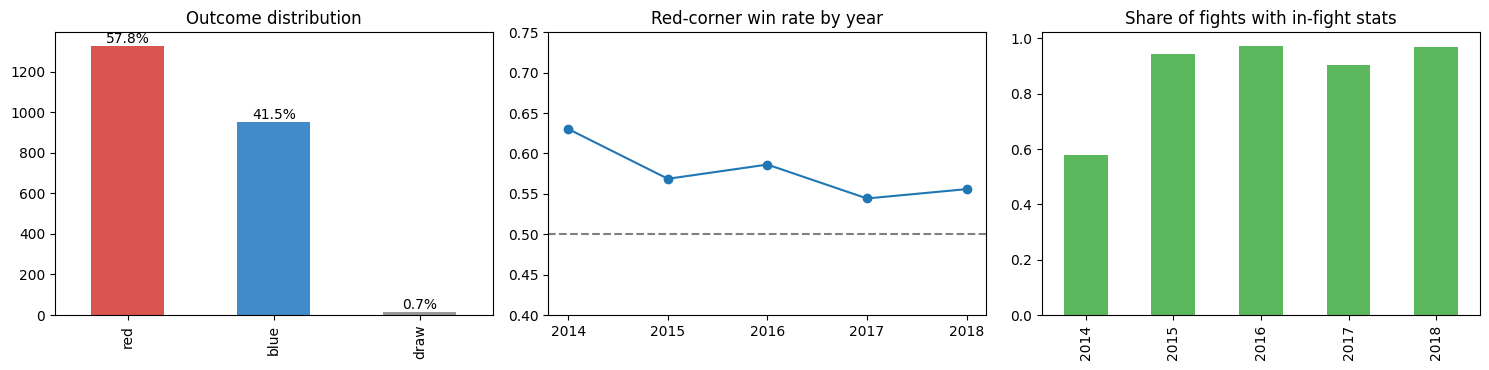

Red wins overall: 57.8%  -> 'always predict red' is the baseline to beat


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))

fights["winner"].value_counts().reindex(["red", "blue", "draw"]).plot.bar(ax=ax[0], color=["#d9534f", "#428bca", "#999"])
ax[0].set_title("Outcome distribution"); ax[0].set_xlabel("")
for i, v in enumerate(fights["winner"].value_counts().reindex(["red", "blue", "draw"])):
    ax[0].text(i, v, f"{v/len(fights):.1%}", ha="center", va="bottom")

yr = fights.groupby(fights["Date"].dt.year)["winner"].apply(lambda s: (s == "red").mean())
yr.plot.line(marker="o", ax=ax[1]); ax[1].set_xticks(list(yr.index)); ax[1].set_ylim(0.4, 0.75); ax[1].axhline(0.5, ls="--", c="grey")
ax[1].set_title("Red-corner win rate by year"); ax[1].set_xlabel("")

fights.groupby(fights["Date"].dt.year)["has_stats"].mean().plot.bar(ax=ax[2], color="#5cb85c")
ax[2].set_title("Share of fights with in-fight stats"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print("Red wins overall: %.1f%%  -> 'always predict red' is the baseline to beat" % (100 * (fights.winner == 'red').mean()))

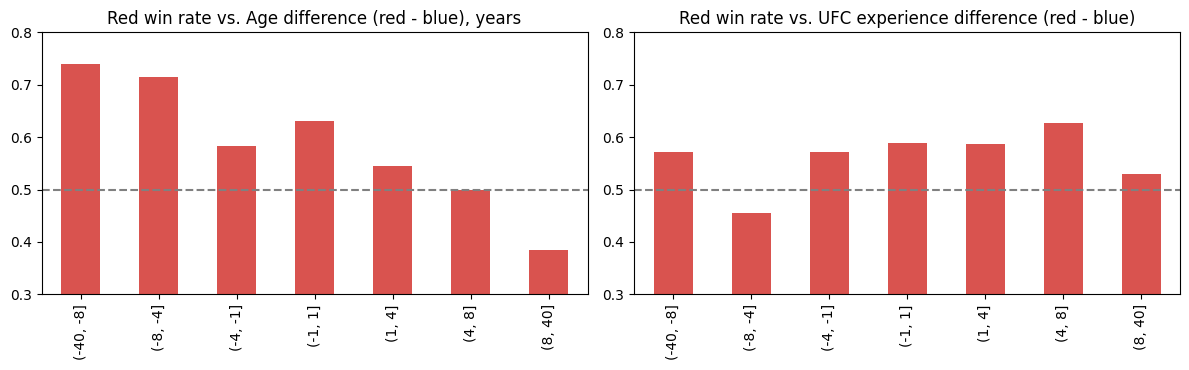

In [11]:
fights["age_diff"] = fights["R_Age"] - fights["B_Age"]
fights["exp_diff"] = fights["RPrev"] - fights["BPrev"]
res = fights[fights.winner != "draw"]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, col, ttl in [(ax[0], "age_diff", "Age difference (red - blue), years"), (ax[1], "exp_diff", "UFC experience difference (red - blue)")]:
    b = pd.cut(res[col], bins=[-40, -8, -4, -1, 1, 4, 8, 40])
    r = res.groupby(b, observed=True)["winner"].agg(lambda s: (s == "red").mean())
    r.plot.bar(ax=a, color="#d9534f"); a.axhline(0.5, ls="--", c="grey")
    a.set_title("Red win rate vs. " + ttl); a.set_xlabel(""); a.set_ylim(0.3, 0.8)
plt.tight_layout(); plt.show()

## 1.4 Leak-free feature engineering (career statistics *before* each fight)

**Idea.** Reshape to one row per *(fighter, fight)*, sort by date, and take running (cumulative) sums of results and in-fight stats. Shifting by one fight gives what was known **before** that fight (fight *n* only sees fights 1…*n*−1).
The same code path builds the fighter *profiles* used later by `predict_fight()` (all fights, no shift).

Per-fighter features (38): age, height, weight, earlier UFC fights, days since last fight, current win/loss streak, number of fights, win/KO/submission/decision/finish/loss-method rates, career averages per fight (14 offensive stats), accuracy & defence (strikes, takedowns), and averages of what opponents did to him (strikes absorbed, knockdowns taken, takedowns conceded…).
The model gets each corner's features (`R_`, `B_`) and their difference (`diff_` = red − blue).

In [12]:
AVG_STATS = ["sig_l", "sig_a", "tot_l", "head_l", "body_l", "leg_l", "dist_l", "clinch_l",
             "ground_l", "kd", "td_l", "td_a", "sub_a", "rev"]
CUM_STATS = list(STATS.keys())
COUNT_COLS = (["n", "win", "loss", "draw", "ko_win", "sub_win", "dec_win", "ko_loss", "sub_loss", "n_stat"]
              + [k + "_sum" for k in CUM_STATS] + ["opp_" + k + "_sum" for k in CUM_STATS])

def build_long(fights, birth_map):
    parts = []
    for side, opp, win_label in (("R", "B", "red"), ("B", "R", "blue")):
        d = pd.DataFrame({
            "Fight_ID": fights["Fight_ID"].values, "Date": fights["Date"].values, "side": side,
            "ID": fights[f"{side}_ID"].values, "Name": fights[f"{side}_Name"].values,
            "age": fights[f"{side}_Age"].values, "height": fights[f"{side}_Height"].values,
            "weight": fights[f"{side}_Weight"].values, "ufc_prev": fights[f"{side}Prev"].values,
            "method": fights["winby"].values, "has_stats": fights["has_stats"].values})
        w = fights["winner"].values
        d["result"] = np.where(w == "draw", "draw", np.where(w == win_label, "win", "loss"))
        d["birth_dec"] = d["ID"].map(birth_map).values
        for k in CUM_STATS:
            d[k + "_sum"] = fights[f"{side}_{k}"].fillna(0).values
            d["opp_" + k + "_sum"] = fights[f"{opp}_{k}"].fillna(0).values
        parts.append(d)
    L = pd.concat(parts, ignore_index=True)
    L["n"] = 1
    for r in ("win", "loss", "draw"):
        L[r] = (L["result"] == r).astype(int)
    L["ko_win"]   = ((L["result"] == "win")  & (L["method"] == "KO/TKO")).astype(int)
    L["sub_win"]  = ((L["result"] == "win")  & (L["method"] == "SUB")).astype(int)
    L["dec_win"]  = ((L["result"] == "win")  & (L["method"] == "DEC")).astype(int)
    L["ko_loss"]  = ((L["result"] == "loss") & (L["method"] == "KO/TKO")).astype(int)
    L["sub_loss"] = ((L["result"] == "loss") & (L["method"] == "SUB")).astype(int)
    L["n_stat"]   = L["has_stats"].astype(int)
    return L.sort_values(["Date", "Fight_ID", "side"]).reset_index(drop=True)

def sdiv(a, b):                       # safe division -> NaN when denominator is 0
    return a / b.where(b > 0)

def derive(c):
    # turn cumulative counts into career features
    o = pd.DataFrame(index=c.index)
    n, ns = c["n"], c["n_stat"]
    o["n_fights"]     = n
    o["win_rate"]     = sdiv(c["win"], n)
    o["ko_win_rate"]  = sdiv(c["ko_win"], n)
    o["sub_win_rate"] = sdiv(c["sub_win"], n)
    o["dec_win_rate"] = sdiv(c["dec_win"], n)
    o["finish_rate"]  = sdiv(c["ko_win"] + c["sub_win"], n)
    o["ko_loss_rate"] = sdiv(c["ko_loss"], n)
    o["sub_loss_rate"] = sdiv(c["sub_loss"], n)
    for k in AVG_STATS:
        o["avg_" + k] = sdiv(c[k + "_sum"], ns)
    o["sig_acc"] = sdiv(c["sig_l_sum"], c["sig_a_sum"])
    o["td_acc"]  = sdiv(c["td_l_sum"], c["td_a_sum"])
    o["sig_def"] = 1 - sdiv(c["opp_sig_l_sum"], c["opp_sig_a_sum"])
    o["td_def"]  = 1 - sdiv(c["opp_td_l_sum"], c["opp_td_a_sum"])
    o["avg_sig_absorbed"]    = sdiv(c["opp_sig_l_sum"], ns)
    o["avg_kd_taken"]        = sdiv(c["opp_kd_sum"], ns)
    o["avg_td_conceded"]     = sdiv(c["opp_td_l_sum"], ns)
    o["avg_sub_att_faced"]   = sdiv(c["opp_sub_a_sum"], ns)
    o["avg_ground_absorbed"] = sdiv(c["opp_ground_l_sum"], ns)
    return o

def streaks(L):
    # win / lose streak *before* each row + the streak after each fighter's last fight
    pre_w = np.zeros(len(L), int); pre_l = np.zeros(len(L), int); final = {}
    res = L["result"].values
    for pid, idx in L.groupby("ID").indices.items():
        w = l = 0
        for i in idx:
            pre_w[i], pre_l[i] = w, l
            if res[i] == "win":    w, l = w + 1, 0
            elif res[i] == "loss": w, l = 0, l + 1
            else:                  w, l = 0, 0
        final[pid] = (w, l)
    return pre_w, pre_l, final

DERIVED_COLS = list(derive(pd.DataFrame({c: [1.0] for c in COUNT_COLS})).columns)
STATIC_COLS  = ["age", "height", "weight", "ufc_prev", "layoff_days", "win_streak", "lose_streak"]
BASE_FEATURES = STATIC_COLS + DERIVED_COLS
print(len(BASE_FEATURES), "features per fighter")

38 features per fighter


In [13]:
long = build_long(fights, birth_map)

cum = long.groupby("ID")[COUNT_COLS].cumsum()                       # includes the current fight
pre = cum.groupby(long["ID"]).shift(1).fillna(0)                     # only PREVIOUS fights
F = derive(pre)
F["age"], F["height"], F["weight"], F["ufc_prev"] = long["age"], long["height"], long["weight"], long["ufc_prev"]
F["layoff_days"] = long.groupby("ID")["Date"].diff().dt.days
pw, pl, _ = streaks(long)
F["win_streak"], F["lose_streak"] = pw, pl
F = F[BASE_FEATURES]

FR = F[long["side"] == "R"].set_index(long.loc[long["side"] == "R", "Fight_ID"]).loc[fights["Fight_ID"]].reset_index(drop=True)
FB = F[long["side"] == "B"].set_index(long.loc[long["side"] == "B", "Fight_ID"]).loc[fights["Fight_ID"]].reset_index(drop=True)

X = pd.concat([FR.add_prefix("R_"), FB.add_prefix("B_"),
               pd.DataFrame(FR.values - FB.values, columns=BASE_FEATURES).add_prefix("diff_")], axis=1)
model_df = pd.concat([fights[["Fight_ID", "Date", "R_Name", "B_Name"]], X, fights["winner"].rename("target")], axis=1)
model_df.to_csv("ufc_model_dataset.csv", index=False)
print("Model dataset:", model_df.shape, "->", X.shape[1], "features; saved to ufc_model_dataset.csv")
print("Missing share per feature (top 8):")
print(X.isna().mean().sort_values(ascending=False).head(8).round(3).to_string())

Model dataset: (2294, 119) -> 114 features; saved to ufc_model_dataset.csv
Missing share per feature (top 8):
diff_td_acc          0.658
diff_sig_acc         0.564
B_td_acc             0.558
diff_td_def          0.548
diff_sig_def         0.500
B_sig_acc            0.481
B_td_def             0.461
diff_avg_ground_l    0.460


### Proof there is no leakage
For a random fight we rebuild both fighters' profiles **using only fights dated before it** (exactly what `predict_fight()` will do) and confirm they equal the training features.

In [14]:
def build_profiles(L_in):
    # career profile of every fighter after ALL fights in L_in (what we know going into their next fight)
    L = L_in.sort_values(["Date", "Fight_ID", "side"]).reset_index(drop=True)
    cum = L.groupby("ID")[COUNT_COLS].cumsum()
    last = cum.groupby(L["ID"]).tail(1)
    P = derive(last.set_index(L.loc[last.index, "ID"].values))
    _, _, fin = streaks(L)
    P["win_streak"]  = pd.Series({k: v[0] for k, v in fin.items()})
    P["lose_streak"] = pd.Series({k: v[1] for k, v in fin.items()})
    lr = L.groupby("ID").tail(1).set_index("ID")
    P["name"], P["last_date"], P["birth_dec"] = lr["Name"], lr["Date"], lr["birth_dec"]
    P["height"], P["weight"], P["ufc_prev"] = lr["height"], lr["weight"], lr["ufc_prev"] + 1
    return P

CHECK_COLS = DERIVED_COLS + ["win_streak", "lose_streak"]
rng = np.random.RandomState(RANDOM_STATE)
ok = 0
cand = model_df.index[(model_df["R_n_fights"] > 2) & (model_df["B_n_fights"] > 2)]
for i in rng.choice(cand, 10, replace=False):
    row = fights.iloc[i]
    P = build_profiles(long[long["Date"] < row["Date"]])
    for side, pid in (("R", row["R_ID"]), ("B", row["B_ID"])):
        got = P.loc[pid, CHECK_COLS].astype(float).values
        exp = model_df.loc[i, [f"{side}_{c}" for c in CHECK_COLS]].astype(float).values
        assert np.allclose(got, exp, equal_nan=True), (i, side)
    ok += 1
print(f"Leakage test passed on {ok} random fights: features == history-before-the-fight only.")

profiles = build_profiles(long)          # profiles after ALL known fights -> used for real predictions
print("Fighter profiles:", profiles.shape)

Leakage test passed on 10 random fights: features == history-before-the-fight only.
Fighter profiles: (1082, 39)


**Part 1 hand-over:** `model_df` (features + `target`), `profiles`, and the helper functions above.  
`model_df` is also saved as `ufc_model_dataset.csv`.

---
# PART 2 — Modelling, evaluation & the prediction function &nbsp;·&nbsp; *Member 2*
## 2.1 Time-based train / test split
Fights are ordered by date. We train on the **older 80%** and test on the **newest 20%** – the model never sees the future, which mirrors real use (and the paper's time-series k-fold). Hyper-parameters are tuned **only inside the training part** with `TimeSeriesSplit`.

In [15]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.linear_model import SGDClassifier, LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, log_loss, confusion_matrix, classification_report, ConfusionMatrixDisplay

feature_cols = [c for c in model_df.columns if c.startswith(("R_", "B_", "diff_")) and c not in ("R_Name", "B_Name")]
data = model_df.sort_values(["Date", "Fight_ID"]).reset_index(drop=True)
X_all, y_all = data[feature_cols], data["target"]

cut = int(len(data) * 0.8)
cut_date = data.loc[cut, "Date"]
train_mask = data["Date"] < cut_date
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test,  y_test  = X_all[~train_mask], y_all[~train_mask]

print(f"{len(feature_cols)} features | train: {len(X_train)} fights ({data.loc[train_mask,'Date'].min().date()} -> {data.loc[train_mask,'Date'].max().date()})")
print(f"                       test : {len(X_test)} fights ({data.loc[~train_mask,'Date'].min().date()} -> {data.loc[~train_mask,'Date'].max().date()})")
print("\nTrain classes:", y_train.value_counts().to_dict(), "| Test classes:", y_test.value_counts().to_dict())

baseline_acc = (y_test == "red").mean()
print(f"\nBaseline 'always predict red' on the test set: {baseline_acc:.3f}")

114 features | train: 1831 fights (2014-01-07 -> 2017-11-13)
                       test : 463 fights (2017-11-20 -> 2018-10-08)

Train classes: {'red': 1070, 'blue': 750, 'draw': 11} | Test classes: {'red': 257, 'blue': 201, 'draw': 5}

Baseline 'always predict red' on the test set: 0.555


## 2.2 Models and hyper-parameter search
Every model sits in the same pipeline: **median imputation → standardisation → classifier** (the paper also centred/scaled inside each fold). Imputer and scaler are fitted only on the training data of each fold.

In [16]:
def pipe(clf):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", clf)])

candidates = {
    "SGD (Perceptron)": (pipe(SGDClassifier(loss="perceptron", max_iter=2000, random_state=RANDOM_STATE)),
                         {"clf__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1.0]}),
    "MLP (L-BFGS)": (pipe(MLPClassifier(solver="lbfgs", max_iter=500, random_state=RANDOM_STATE)),
                     {"clf__hidden_layer_sizes": [(5, 2), (16, 8), (32, 16)], "clf__alpha": [1e-2, 1.0, 10.0]}),
    "Decision Tree (pruned)": (pipe(DecisionTreeClassifier(random_state=RANDOM_STATE)),
                               {"clf__ccp_alpha": [0, 0.001, 0.003, 0.005, 0.01], "clf__max_depth": [3, 5, 8, None]}),
    "Gradient Boosting": (pipe(GradientBoostingClassifier(subsample=0.8, random_state=RANDOM_STATE)),
                          {"clf__learning_rate": [0.01, 0.05], "clf__n_estimators": [100, 300], "clf__max_depth": [2, 3]}),
    "Logistic Regression": (pipe(LogisticRegression(max_iter=3000)),
                            {"clf__C": [0.001, 0.01, 0.1, 1.0]}),
    "Random Forest": (pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
                      {"clf__max_depth": [4, 8, None], "clf__min_samples_leaf": [3, 10]}),
}

tscv = TimeSeriesSplit(n_splits=5)
searches, rows = {}, []
for name, (p, grid) in candidates.items():
    gs = GridSearchCV(p, grid, cv=tscv, scoring="accuracy", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    best = gs.best_estimator_
    pred = best.predict(X_test)
    proba_ok = hasattr(best, "predict_proba")
    rows.append({
        "Model": name,
        "Best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
        "CV acc (train, time-series)": gs.best_score_,
        "Train acc": accuracy_score(y_train, best.predict(X_train)),
        "Test acc": accuracy_score(y_test, pred),
        "Test macro-F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Test log-loss": log_loss(y_test, best.predict_proba(X_test), labels=list(best.classes_)) if proba_ok else np.nan,
    })
    print(f"done: {name:24s} CV={gs.best_score_:.3f}  test={rows[-1]['Test acc']:.3f}")

results = pd.DataFrame(rows).set_index("Model")
results.loc["Baseline: always red"] = [{}, np.nan, np.nan, baseline_acc, np.nan, np.nan]

done: SGD (Perceptron)         CV=0.535  test=0.510
done: MLP (L-BFGS)             CV=0.544  test=0.549
done: Decision Tree (pruned)   CV=0.559  test=0.555
done: Gradient Boosting        CV=0.575  test=0.562
done: Logistic Regression      CV=0.570  test=0.585
done: Random Forest            CV=0.584  test=0.575


## 2.3 Results

In [17]:
show = results.drop(columns="Best params").round(3)
display(show.sort_values("Test acc", ascending=False))
print("\nBest hyper-parameters:")
for m, r in results.iterrows():
    if r["Best params"]: print(f"  {m:24s} {r['Best params']}")

,"CV acc (train, time-series)",Train acc,Test acc,Test macro-F1,Test log-loss
Model,,,,,
Logistic Regression,0.570,0.620,0.585,0.341,0.724
Random Forest,0.584,0.837,0.575,0.334,0.729
Gradient Boosting,0.575,0.618,0.562,0.288,0.731
Decision Tree (pruned),0.559,0.584,0.555,0.238,0.733
Baseline: always red,NaN,NaN,0.555,NaN,NaN
MLP (L-BFGS),0.544,0.946,0.549,0.361,2.814
SGD (Perceptron),0.535,0.582,0.510,0.342,NaN



Best hyper-parameters:
  SGD (Perceptron)         {'alpha': 0.01}
  MLP (L-BFGS)             {'alpha': 10.0, 'hidden_layer_sizes': (16, 8)}
  Decision Tree (pruned)   {'ccp_alpha': 0.01, 'max_depth': 3}
  Gradient Boosting        {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}
  Logistic Regression      {'C': 0.001}
  Random Forest            {'max_depth': None, 'min_samples_leaf': 10}


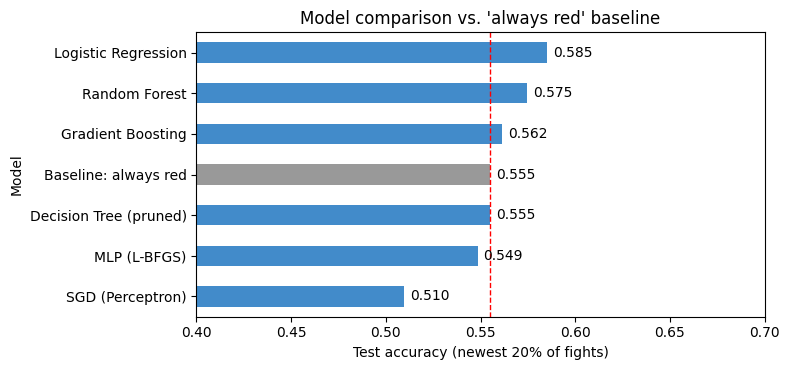

In [18]:
plot_df = results["Test acc"].sort_values()
colors = ["#999" if "Baseline" in i else "#428bca" for i in plot_df.index]
ax = plot_df.plot.barh(color=colors, figsize=(8, 3.8))
ax.axvline(baseline_acc, ls="--", c="red", lw=1)
ax.set_xlim(0.4, max(0.7, plot_df.max() + 0.03)); ax.set_xlabel("Test accuracy (newest 20% of fights)")
for i, v in enumerate(plot_df.values): ax.text(v + 0.003, i, f"{v:.3f}", va="center")
plt.title("Model comparison vs. 'always red' baseline"); plt.tight_layout(); plt.show()

### Best model (chosen by **cross-validation on the training data only**, never by looking at the test set)

Best by CV: Random Forest
Test accuracy 0.575  (95% CI about 0.529 - 0.620, n=463)

               precision    recall  f1-score   support

        blue       0.56      0.21      0.31       201
        draw       0.00      0.00      0.00         5
         red       0.58      0.87      0.69       257

    accuracy                           0.57       463
   macro avg       0.38      0.36      0.33       463
weighted avg       0.56      0.57      0.52       463



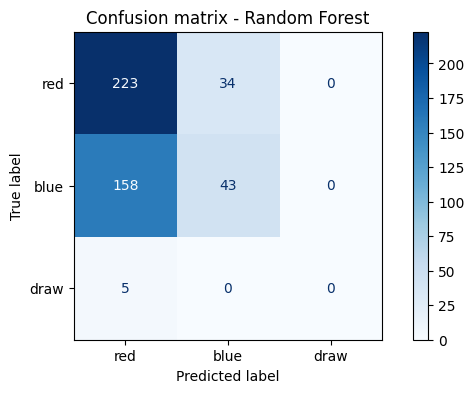

In [19]:
best_name = results.drop(index="Baseline: always red")["CV acc (train, time-series)"].astype(float).idxmax()
best_model = searches[best_name].best_estimator_
pred = best_model.predict(X_test)
acc = accuracy_score(y_test, pred); se = np.sqrt(acc * (1 - acc) / len(y_test))
print(f"Best by CV: {best_name}")
print(f"Test accuracy {acc:.3f}  (95% CI about {acc-1.96*se:.3f} - {acc+1.96*se:.3f}, n={len(y_test)})")
print("\n", classification_report(y_test, pred, zero_division=0))

labels = ["red", "blue", "draw"]
ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=labels), display_labels=labels).plot(cmap="Blues", values_format="d")
plt.title(f"Confusion matrix - {best_name}"); plt.show()

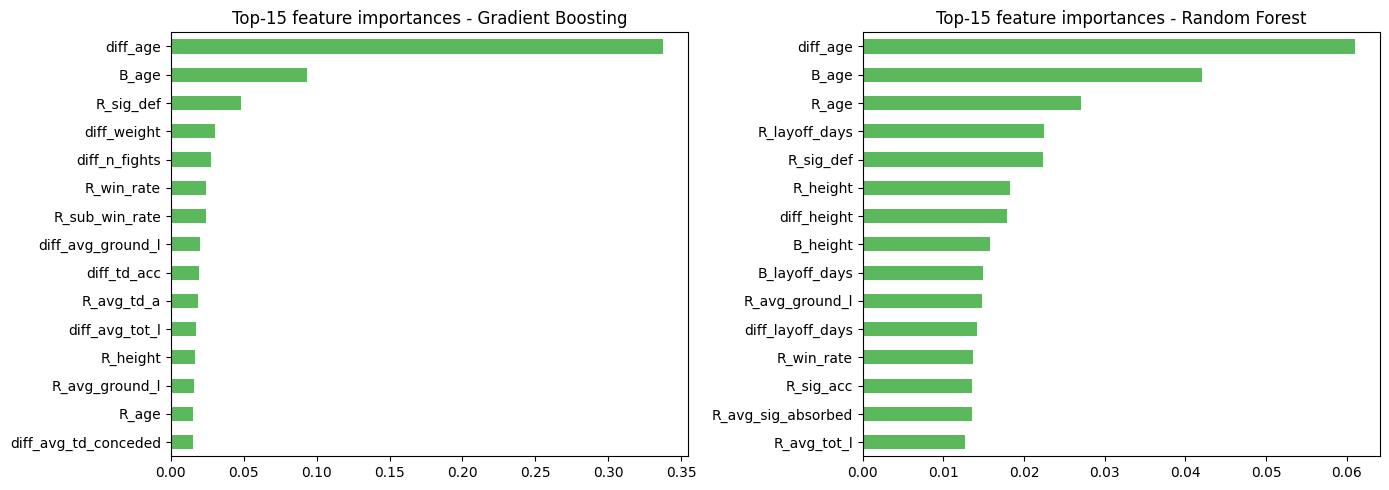

In [20]:
# Which features matter? (tree-based models expose importances)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, m in zip(axes, ["Gradient Boosting", "Random Forest"]):
    imp = pd.Series(searches[m].best_estimator_.named_steps["clf"].feature_importances_, index=feature_cols).sort_values().tail(15)
    imp.plot.barh(ax=ax, color="#5cb85c"); ax.set_title(f"Top-15 feature importances - {m}")
plt.tight_layout(); plt.show()

## 2.4 Train the deployment model on all data and save it
The chosen configuration is refitted on **all** fights (train + test) so the predictor uses the most recent information. Its hyper-parameters come from the search above.

In [21]:
final_model = clone(best_model).fit(X_all, y_all)
joblib.dump({"model": final_model, "feature_cols": feature_cols, "base_features": BASE_FEATURES,
             "profiles": profiles, "model_name": best_name}, "ufc_model.joblib")
print(f"Deployed model: {best_name} | classes: {list(final_model.classes_)} | saved to ufc_model.joblib")

Deployed model: Random Forest | classes: ['blue', 'draw', 'red'] | saved to ufc_model.joblib


## 2.5 `predict_fight()` – predict any UFC fight
Give two fighter names (any spelling that is close enough is matched) and the corner they fight from (**red = first argument**; the red corner is normally the favourite/higher-ranked fighter, so the corner is itself informative).

* `fight_date` (optional, e.g. `"2019-03-02"`) → ages the fighters and computes the layoff; without it, the age at their last recorded fight is used.
* `red_overrides` / `blue_overrides` (optional) → replace stale values, e.g. `{"age": 34, "weight": 77, "ufc_prev": 12}`.

Only fighters who appear in the dataset can be predicted, because the model needs their fight history.

In [22]:
# name lookup: every spelling seen in the data -> fighter ID (the same fighter can appear under two spellings)
def norm(s): return " ".join(str(s).lower().replace(".", "").replace("-", " ").split())
_names = pd.concat([fights[["R_ID", "R_Name"]].set_axis(["ID", "name"], axis=1),
                    fights[["B_ID", "B_Name"]].set_axis(["ID", "name"], axis=1)]).drop_duplicates()
_names["key"] = _names["name"].map(norm)
_names["n"] = _names["ID"].map(profiles["n_fights"])
name_to_id = _names.sort_values("n", ascending=False).drop_duplicates("key").set_index("key")["ID"].to_dict()

def resolve_fighter(name):
    k = norm(name)
    if k in name_to_id:
        fid = name_to_id[k]
    else:
        close = difflib.get_close_matches(k, list(name_to_id), n=3, cutoff=0.75)
        if not close:
            raise ValueError(f"'{name}' not found in the dataset (fighters must have fought in it).")
        if len(close) > 1 and difflib.SequenceMatcher(None, k, close[0]).ratio() < 0.9:
            raise ValueError(f"'{name}' is ambiguous - did you mean: {[profiles.loc[name_to_id[c],'name'] for c in close]}?")
        fid = name_to_id[close[0]]
    return fid, profiles.loc[fid, "name"]

def fighter_base_features(p, fight_date=None, over=None):
    f = {c: p[c] for c in DERIVED_COLS}
    f["win_streak"], f["lose_streak"] = p["win_streak"], p["lose_streak"]
    if fight_date is not None:
        fd = pd.Timestamp(fight_date)
        f["age"] = round((fd.year + (fd.dayofyear - 1) / 365.25) - p["birth_dec"])
        f["layoff_days"] = (fd - p["last_date"]).days
    else:
        ld = p["last_date"]
        f["age"] = round((ld.year + (ld.dayofyear - 1) / 365.25) - p["birth_dec"])
        f["layoff_days"] = np.nan                                   # unknown -> imputed by the model
    f["height"], f["weight"], f["ufc_prev"] = p["height"], p["weight"], p["ufc_prev"]
    f.update(over or {})
    return pd.Series(f)[BASE_FEATURES].astype(float)

def predict_fight(red, blue, fight_date=None, red_overrides=None, blue_overrides=None, model=None, verbose=True):
    model = model or final_model
    rid, rname = resolve_fighter(red); bid, bname = resolve_fighter(blue)
    if rid == bid: raise ValueError("Red and blue must be different fighters.")
    fr = fighter_base_features(profiles.loc[rid], fight_date, red_overrides)
    fb = fighter_base_features(profiles.loc[bid], fight_date, blue_overrides)
    row = pd.concat([fr.add_prefix("R_"), fb.add_prefix("B_"), (fr - fb).add_prefix("diff_")])[feature_cols].to_frame().T
    label = model.predict(row)[0]
    out = {"red": rname, "blue": bname, "prediction": label,
           "winner": rname if label == "red" else bname if label == "blue" else "Draw"}
    if hasattr(model, "predict_proba"):
        out["probabilities"] = dict(zip(model.classes_, np.round(model.predict_proba(row)[0], 3)))
    if verbose:
        print(f"RED: {rname}   vs   BLUE: {bname}")
        print(f"Predicted outcome: {out['winner']}  ({label})")
        if "probabilities" in out:
            print("Probabilities:", {k: f'{v:.1%}' for k, v in out['probabilities'].items()})
    return out

### Demo (fighters are picked automatically from the dataset, so this cell always runs)
The second call swaps the corners on purpose: the model treats the **red corner as informative** (red is usually the favourite / higher-ranked fighter and wins ~58 % of the time), so the same matchup can get different probabilities depending on who is in which corner.

In [23]:
active = profiles[profiles["n_fights"] >= 5].sort_values("n_fights", ascending=False)
a = active.iloc[0]
b = active[(active.index != a.name) & ((active["weight"] - a["weight"]).abs() <= 3)].iloc[0]
_ = predict_fight(a["name"], b["name"])
print()
_ = predict_fight(b["name"], a["name"], fight_date="2019-03-02")   # swapped corners + explicit date

RED: Donald Cerrone   vs   BLUE: Neil Magny
Predicted outcome: Neil Magny  (blue)
Probabilities: {'blue': '50.4%', 'draw': '0.9%', 'red': '48.8%'}

RED: Neil Magny   vs   BLUE: Donald Cerrone
Predicted outcome: Neil Magny  (red)
Probabilities: {'blue': '32.2%', 'draw': '0.7%', 'red': '67.1%'}


In [24]:
# Try your own fight (uncomment):
# predict_fight("Fighter One", "Fighter Two")
predict_fight(input("Red corner: "), input("Blue corner: "), fight_date="2019-03-02", red_overrides={"age": 33})

ValueError: '' not found in the dataset (fighters must have fought in it).

## 2.6 Sanity check of the saved model file

In [25]:
bundle = joblib.load("ufc_model.joblib")
print("Reloaded:", bundle["model_name"], "| features:", len(bundle["feature_cols"]), "| fighters in profile table:", len(bundle["profiles"]))
same = (bundle["model"].predict(X_test) == final_model.predict(X_test)).all()
print("Reloaded model gives identical predictions:", same)

Reloaded: Random Forest | features: 114 | fighters in profile table: 1082
Reloaded model gives identical predictions: True


---
## Conclusions

In [26]:
r = results.drop(index="Baseline: always red")
top = r["Test acc"].astype(float).sort_values(ascending=False)
print(f"* Best model by cross-validation: {best_name}  (test accuracy {acc:.1%}).")
print(f"* Best test accuracy of any model: {top.index[0]} {top.iloc[0]:.1%};  worst: {top.index[-1]} {top.iloc[-1]:.1%};  'always red' baseline: {baseline_acc:.1%}.")
print(f"* Test set size is {len(y_test)} fights, so differences of ~2-3 points between models are within statistical noise.")

* Best model by cross-validation: Random Forest  (test accuracy 57.5%).
* Best test accuracy of any model: Logistic Regression 58.5%;  worst: SGD (Perceptron) 51.0%;  'always red' baseline: 55.5%.
* Test set size is 463 fights, so differences of ~2-3 points between models are within statistical noise.


**Discussion**
* **Approach.** The raw file is post-fight data with messy dates, so cleaning and *career-history* features (built only from earlier fights, verified by the leakage test) were essential. Feeding the in-fight stats directly would give impressive but meaningless accuracy.
* **Results.** On the newest 20 % of fights the six models score between **51.0 % and 58.5 %**, against **55.5 %** for "always predict red". The model chosen by cross-validation (Random Forest, 57.5 %) is only ~2 points above that baseline, and with 463 test fights the 95 % interval (~53–62 %) still contains the baseline. So the honest conclusion is: *these stats give a small edge at best*. The paper reports the same pattern (58–61 % for its models, below its 62.6 % red-corner baseline). Simple, heavily regularised models (Logistic Regression, Random Forest) beat the MLP (which over-fits: ~80 % train vs ~52 % test accuracy) and the perceptron (~51 %) on ~1.8k training fights with 114 features.
* **What matters.** In both tree ensembles the **age difference** dominates by a wide margin, followed by the fighters' ages, striking defence, layoff time, height and win rate. This agrees with the paper's finding that age and significant-strike statistics are the key features.
* **Draws.** Only 16 fights (0.7 %) are draws, so no model can learn them; the class is kept for fidelity with the paper's 3-class set-up but its precision/recall is 0 and the predictor effectively chooses between red and blue.
* **Limitations.** Only 2014-2018 (~2.3k fights), so career histories are truncated and many fighters are effectively debuting (missing values imputed with the training median). ~13 % of fights have no in-fight stats and 21 % of the raw dates were corrupted (repaired via event consensus). Fighters absent from the dataset cannot be predicted. Reach, stance, betting odds, rankings and injuries are not available.
* **Future work.** Add reach/stance and betting odds, Elo-style ratings, per-minute rates, more history (1993-2019), probability calibration, and predict the finishing method.